In [1]:
# ============================================================
# CELL 1 — IMPORTS & CONFIG
# ============================================================
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import (GlobalAveragePooling2D, Dense, Dropout,
                                      RandomFlip, RandomRotation, RandomZoom, RandomContrast)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

print("TensorFlow:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))

# ---- Paths (same dataset root as Review-1) ----
DATASET_ROOT = ("/kaggle/input/datasets/aryashah2k/indian-medicinal-leaves-dataset/"
                 "Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset")
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---- Config ----
IMG_SIZE = 224          # VGG16's native input size
BATCH_SIZE = 32
RANDOM_STATE = 42       # MUST match Review-1 / teammates' notebooks for a fair comparison
TEST_SIZE = 0.30        # -> 70% train, then split remainder 50/50 -> 15% val, 15% test
AUTOTUNE = tf.data.AUTOTUNE

MODEL_TAG = "VGG16"
print("Config loaded. Dataset root:")
print(DATASET_ROOT)


TensorFlow: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Config loaded. Dataset root:
/kaggle/input/datasets/aryashah2k/indian-medicinal-leaves-dataset/Indian Medicinal Leaves Image Datasets/Medicinal Leaf dataset


In [2]:
# ============================================================
# CELL 2 — DATA COLLECTION (identical logic to Review-1, Cell 2)
# ============================================================
def collect_image_paths(root_dir, max_per_class=None):
    records = []
    class_dirs = sorted([d for d in glob.glob(os.path.join(root_dir, "*")) if os.path.isdir(d)])
    print(f"Found {len(class_dirs)} class folders.")
    for class_dir in class_dirs:
        label = os.path.basename(class_dir)
        paths = (glob.glob(os.path.join(class_dir, "*.jpg")) +
                  glob.glob(os.path.join(class_dir, "*.jpeg")) +
                  glob.glob(os.path.join(class_dir, "*.png")) +
                  glob.glob(os.path.join(class_dir, "*.JPG")))
        if max_per_class:
            paths = paths[:max_per_class]
        for p in paths:
            records.append((p, label))
    print(f"Total images collected: {len(records)}")
    return records


records = collect_image_paths(DATASET_ROOT)
if len(records) == 0:
    raise RuntimeError("No images found — double check DATASET_ROOT matches the actual Kaggle input path "
                        "(right-click the dataset in the Kaggle sidebar -> Copy file path).")

image_paths = np.array([r[0] for r in records])
raw_labels = [r[1] for r in records]

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(raw_labels)
NUM_CLASSES = len(label_encoder.classes_)
N = len(records)
print(f"Encoded {NUM_CLASSES} classes. Total samples: {N}")


Found 80 class folders.
Total images collected: 6900
Encoded 80 classes. Total samples: 6900


In [3]:
# ============================================================
# CELL 3 — THREE-WAY STRATIFIED SPLIT (TRAIN / VAL / TEST) — same as Review-1
# ============================================================
all_indices = np.arange(N)

TRAIN_IDX, temp_idx, y_train_full, y_temp = train_test_split(
    all_indices, y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_all
)
VAL_IDX, TEST_IDX, y_val_full, y_test_full = train_test_split(
    temp_idx, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"TRAIN:      {len(TRAIN_IDX):5d} images ({len(TRAIN_IDX)/N*100:.1f}%)")
print(f"VALIDATION: {len(VAL_IDX):5d} images ({len(VAL_IDX)/N*100:.1f}%)")
print(f"TEST:       {len(TEST_IDX):5d} images ({len(TEST_IDX)/N*100:.1f}%)")

assert len(set(TRAIN_IDX) & set(VAL_IDX)) == 0
assert len(set(TRAIN_IDX) & set(TEST_IDX)) == 0
assert len(set(VAL_IDX) & set(TEST_IDX)) == 0
print("No overlap between splits — confirmed.")

y_tr, y_va, y_te = y_all[TRAIN_IDX], y_all[VAL_IDX], y_all[TEST_IDX]
paths_tr, paths_va, paths_te = image_paths[TRAIN_IDX], image_paths[VAL_IDX], image_paths[TEST_IDX]


TRAIN:       4830 images (70.0%)
VALIDATION:  1035 images (15.0%)
TEST:        1035 images (15.0%)
No overlap between splits — confirmed.


In [4]:
# ============================================================
# CELL 4 — tf.data PIPELINE (decode -> resize -> augment(train only) -> VGG16 preprocess)
# ============================================================
augmenter = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.08),
    RandomZoom(0.10),
    RandomContrast(0.10),
], name="augmentation")


def decode_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img


def make_dataset(paths, labels, training):
    paths = tf.constant(paths)
    labels = tf.constant(labels, dtype=tf.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, l: (decode_img(p), l), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, l: (augmenter(x, training=True), l), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, l: (preprocess_input(x), l), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(paths_tr, y_tr, training=True)
val_ds = make_dataset(paths_va, y_va, training=False)
test_ds = make_dataset(paths_te, y_te, training=False)

print("Pipelines built.")


I0000 00:00:1790222316.406908      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790222316.409906      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Pipelines built.


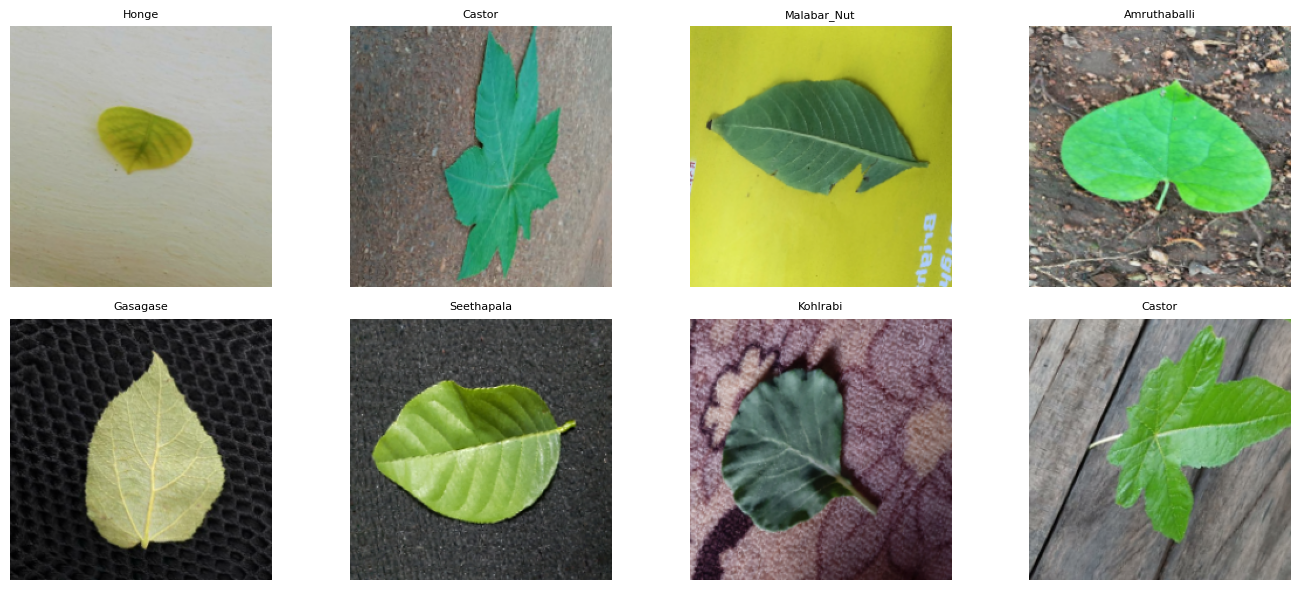

In [5]:
# ============================================================
# CELL 4A — SANITY CHECK: view one augmented training batch
# ============================================================
# preprocess_input subtracts ImageNet channel means, so we undo that just for display.
VGG_MEANS = np.array([103.939, 116.779, 123.68])

for xb, yb in train_ds.take(1):
    xb = xb.numpy()
    plt.figure(figsize=(14, 6))
    for i in range(min(8, xb.shape[0])):
        img = xb[i][..., ::-1] + VGG_MEANS[::-1]   # BGR->RGB, undo mean-subtraction
        img = np.clip(img, 0, 255).astype("uint8")
        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(label_encoder.classes_[yb[i].numpy()], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [6]:
# ============================================================
# CELL 5 — BUILD VGG16 MODEL (transfer learning head)
# ============================================================
def build_vgg16(num_classes, img_size=IMG_SIZE):
    base = VGG16(include_top=False, weights="imagenet",
                 input_shape=(img_size, img_size, 3))
    base.trainable = False  # freeze for stage 1

    x = base.output
    x = GlobalAveragePooling2D(name="gap")(x)
    x = Dense(512, activation="relu", name="fc1")(x)
    x = Dropout(0.4, name="dropout")(x)
    outputs = Dense(num_classes, activation="softmax", name="predictions")(x)

    model = Model(inputs=base.input, outputs=outputs, name="VGG16_transfer")
    return model, base


model, vgg_base = build_vgg16(NUM_CLASSES)
model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "VGG16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 80)             │        41,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,018,384 (57.29 MB)

 Trainable params: 303,696 (1.16 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [7]:
# ============================================================
# CELL 6 — STAGE 1: TRAIN THE CLASSIFIER HEAD (base frozen)
# ============================================================
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_stage1 = [
    EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    ModelCheckpoint(os.path.join(OUTPUT_DIR, "vgg16_stage1_best.keras"),
                     monitor="val_accuracy", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]

EPOCHS_STAGE1 = 15
start = time.time()
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)
print(f"Stage 1 (frozen base) done in {(time.time()-start)/60:.1f} min")


Epoch 1/15
  1/151 ━━━━━━━━━━━━━━━━━━━━ 39:38 16s/step - accuracy: 0.0000e+00 - loss: 7.1653

I0000 00:00:1790222370.052963     133 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 18/151 ━━━━━━━━━━━━━━━━━━━━ 1:28 662ms/step - accuracy: 0.0138 - loss: 6.9423

Corrupt JPEG data: 445 extraneous bytes before marker 0xd9


 61/151 ━━━━━━━━━━━━━━━━━━━━ 1:03 706ms/step - accuracy: 0.0476 - loss: 5.8171

...

139/151 ━━━━━━━━━━━━━━━━━━━━ 7s 662ms/step - accuracy: 0.8975 - loss: 0.3298

Corrupt JPEG data: premature end of data segment


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.8972 - loss: 0.3311

Corrupt JPEG data: premature end of data segment


151/151 ━━━━━━━━━━━━━━━━━━━━ 116s 770ms/step - accuracy: 0.8934 - loss: 0.3471 - val_accuracy: 0.8300 - val_loss: 0.6820 - learning_rate: 0.0010
Stage 1 (frozen base) done in 31.1 min


In [8]:
# ============================================================
# CELL 7 — STAGE 2: FINE-TUNE — unfreeze the last conv block (block5)
# ============================================================
vgg_base.trainable = True
FINE_TUNE_FROM = "block5_conv1"   # keep block1-4 frozen, fine-tune block5 + head

set_trainable = False
for layer in vgg_base.layers:
    if layer.name == FINE_TUNE_FROM:
        set_trainable = True
    layer.trainable = set_trainable

trainable_count = sum(1 for l in vgg_base.layers if l.trainable)
print(f"Unfrozen {trainable_count} layers from '{FINE_TUNE_FROM}' onward.")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # small LR for fine-tuning
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_stage2 = [
    EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    ModelCheckpoint(os.path.join(OUTPUT_DIR, "vgg16_final_best.keras"),
                     monitor="val_accuracy", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
]

EPOCHS_STAGE2 = 10
start = time.time()
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)
print(f"Stage 2 (fine-tune block5) done in {(time.time()-start)/60:.1f} min")


Unfrozen 4 layers from 'block5_conv1' onward.
Epoch 1/10
 19/151 ━━━━━━━━━━━━━━━━━━━━ 1:17 585ms/step - accuracy: 0.8992 - loss: 0.3426

Corrupt JPEG data: premature end of data segment


111/151 ━━━━━━━━━━━━━━━━━━━━ 26s 656ms/step - accuracy: 0.9097 - loss: 0.2952

Corrupt JPEG data: 445 extraneous bytes before marker 0xd9


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 685ms/step - accuracy: 0.9118 - loss: 0.2867

...

145/151 ━━━━━━━━━━━━━━━━━━━━ 4s 671ms/step - accuracy: 0.9716 - loss: 0.0875

Corrupt JPEG data: 445 extraneous bytes before marker 0xd9


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 671ms/step - accuracy: 0.9715 - loss: 0.0875

Corrupt JPEG data: premature end of data segment


151/151 ━━━━━━━━━━━━━━━━━━━━ 142s 787ms/step - accuracy: 0.9696 - loss: 0.0890 - val_accuracy: 0.8937 - val_loss: 0.4640 - learning_rate: 1.0000e-05
Stage 2 (fine-tune block5) done in 20.8 min


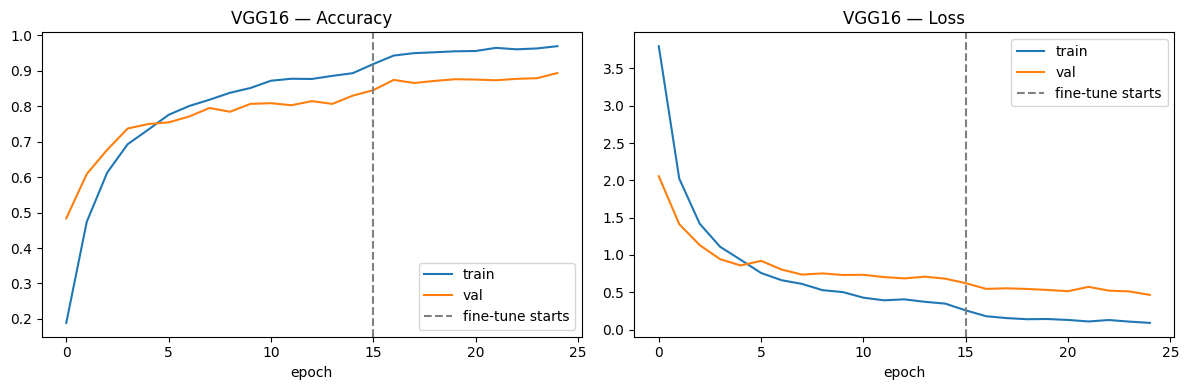

In [9]:
# ============================================================
# CELL 8 — TRAINING CURVES (both stages stitched together)
# ============================================================
def stitch(hist_list, key):
    out = []
    for h in hist_list:
        out.extend(h.history[key])
    return out

acc = stitch([history1, history2], "accuracy")
val_acc = stitch([history1, history2], "val_accuracy")
loss = stitch([history1, history2], "loss")
val_loss = stitch([history1, history2], "val_loss")
switch_epoch = len(history1.history["accuracy"])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label="train")
plt.plot(val_acc, label="val")
plt.axvline(switch_epoch, color="gray", linestyle="--", label="fine-tune starts")
plt.title("VGG16 — Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="train")
plt.plot(val_loss, label="val")
plt.axvline(switch_epoch, color="gray", linestyle="--", label="fine-tune starts")
plt.title("VGG16 — Loss"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "vgg16_training_curves.png"), dpi=150)
plt.show()


In [10]:
# ============================================================
# CELL 9 — FINAL TEST EVALUATION (unseen data)
# ============================================================
y_test_pred_probs = model.predict(test_ds)
y_test_pred = np.argmax(y_test_pred_probs, axis=1)

test_acc = accuracy_score(y_te, y_test_pred)
test_prec = precision_score(y_te, y_test_pred, average="macro", zero_division=0)
test_rec = recall_score(y_te, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_te, y_test_pred, average="macro", zero_division=0)

print("=" * 60)
print(f"FINAL TEST RESULTS — {MODEL_TAG}")
print("=" * 60)
print(f"Accuracy:         {test_acc:.4f}")
print(f"Precision(macro): {test_prec:.4f}")
print(f"Recall(macro):    {test_rec:.4f}")
print(f"F1(macro):        {test_f1:.4f}")
print()
print(classification_report(y_te, y_test_pred, target_names=label_encoder.classes_, zero_division=0))


33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 576ms/step
FINAL TEST RESULTS — VGG16
Accuracy:         0.8995
Precision(macro): 0.9083
Recall(macro):    0.8992
F1(macro):        0.8971

                         precision    recall  f1-score   support

               Aloevera       1.00      0.76      0.87        17
                   Amla       0.89      0.80      0.84        10
           Amruthaballi       1.00      0.93      0.96        14
                  Arali       1.00      1.00      1.00        14
             Astma_weed       1.00      0.85      0.92        13
               Badipala       0.89      0.73      0.80        11
           Balloon_Vine       0.78      0.78      0.78         9
                 Bamboo       0.85      1.00      0.92        17
                  Beans       0.93      0.93      0.93        15
                  Betel       0.83      0.88      0.86        17
                 Bhrami       0.93      0.81      0.87        16
             Bringaraja       0.88      0.64     

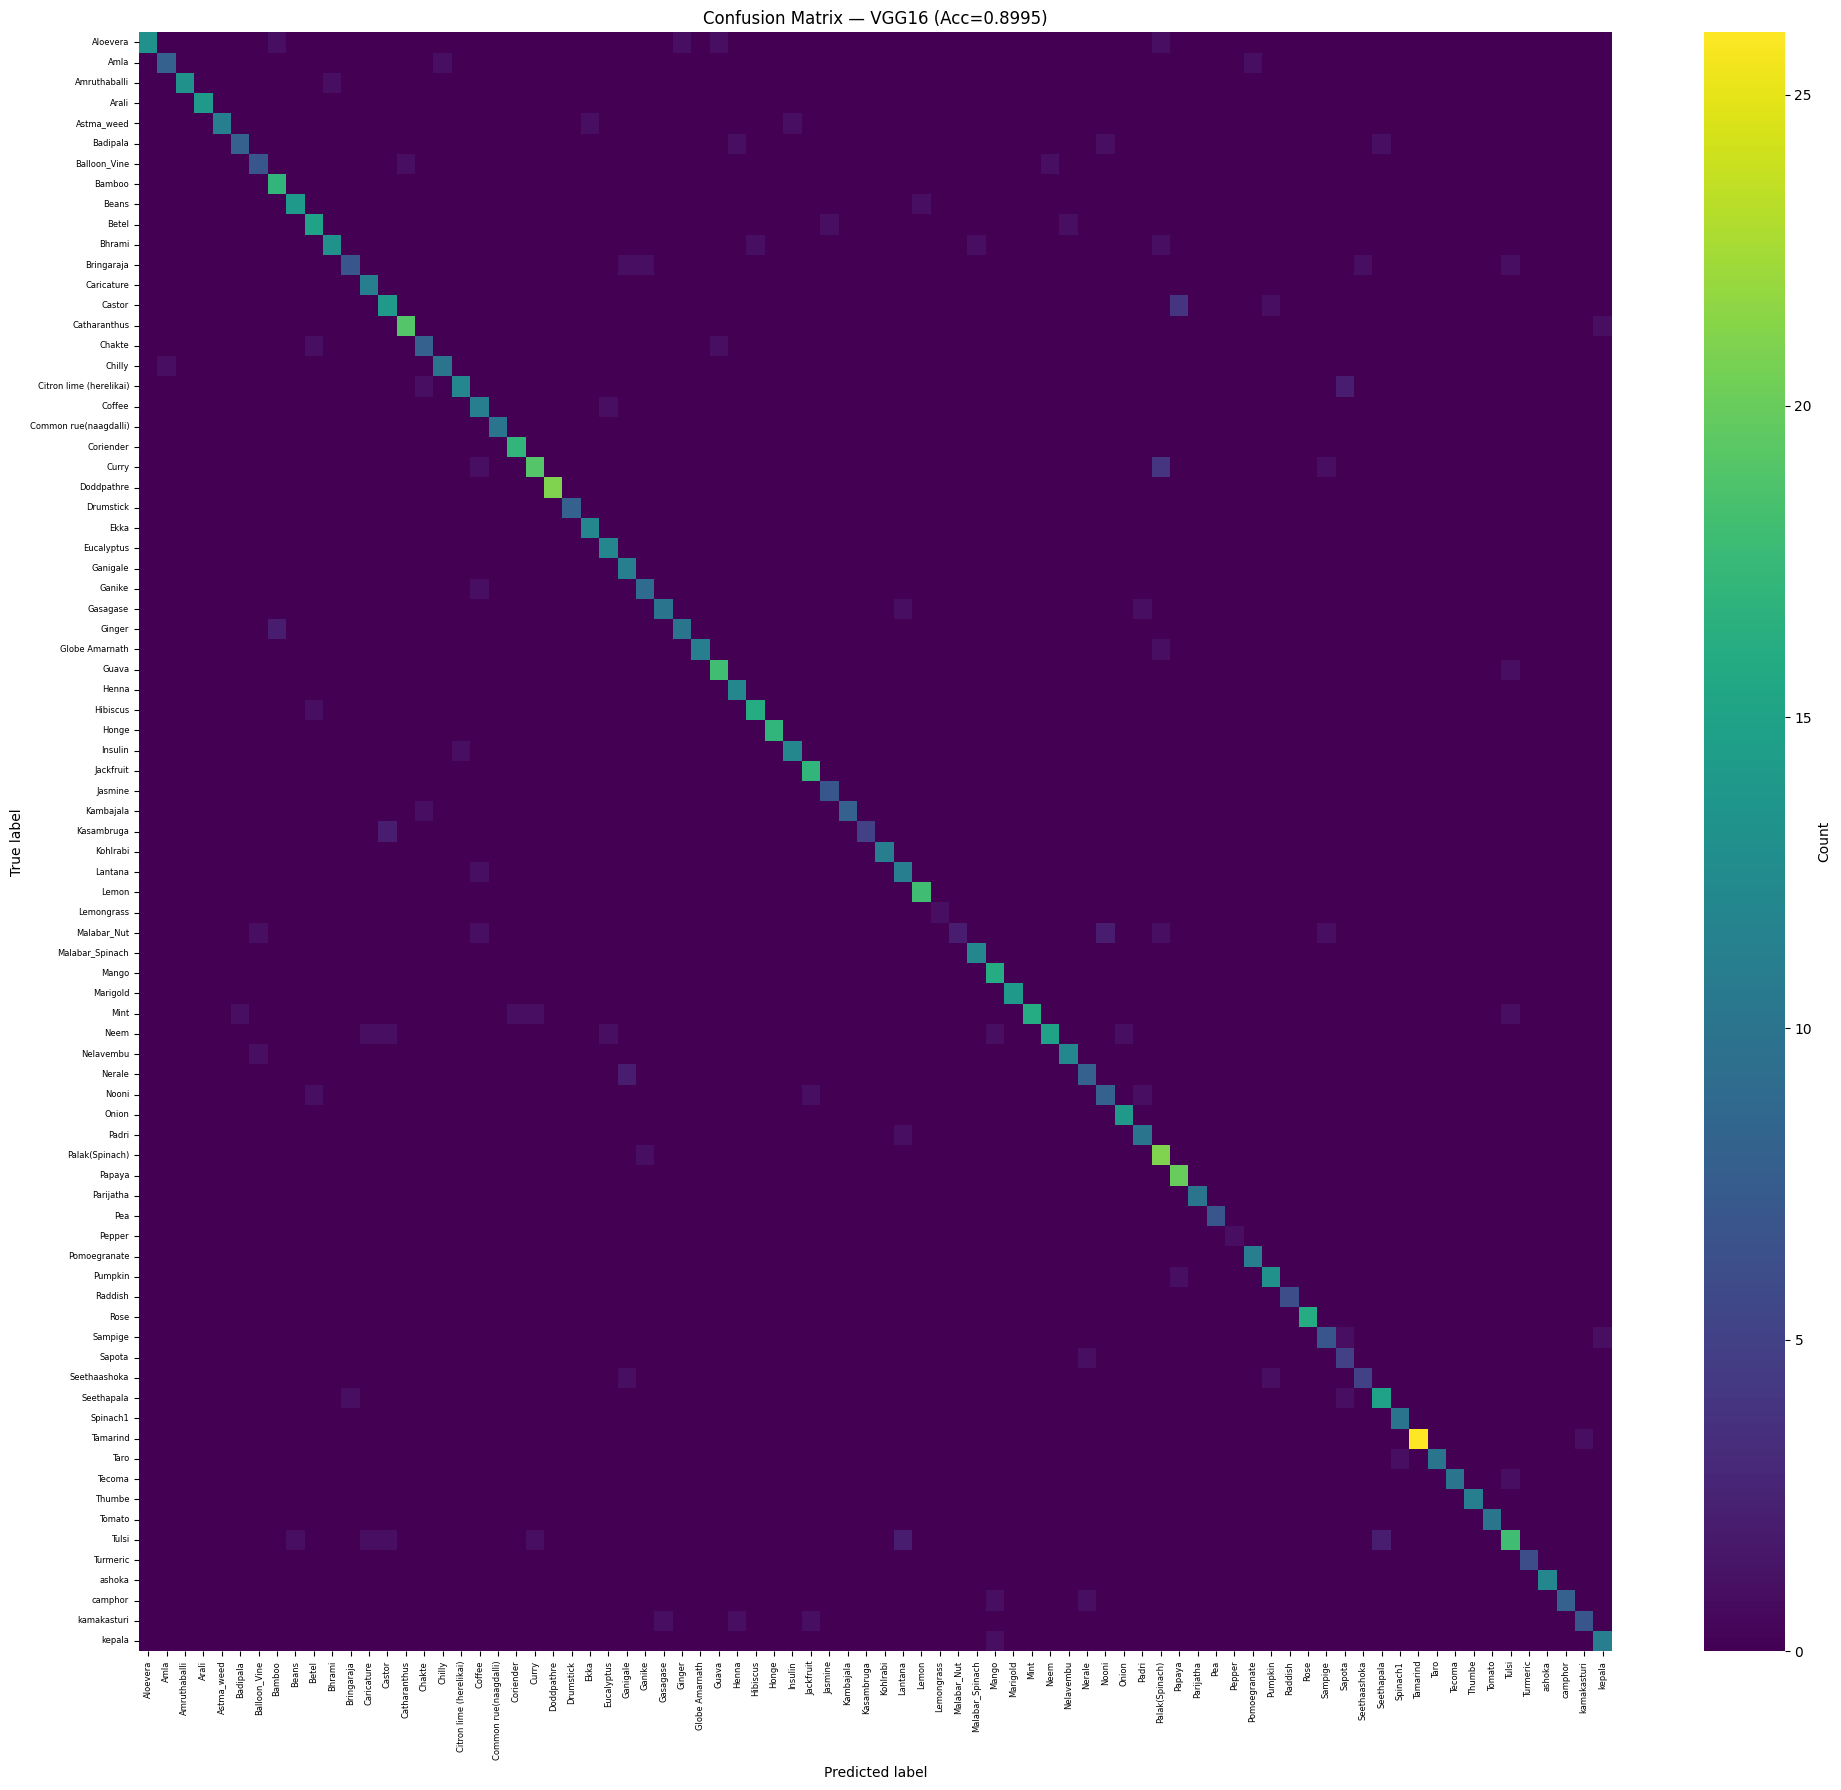

In [11]:
# ============================================================
# CELL 10 — CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_te, y_test_pred)

plt.figure(figsize=(20, 18))
sns.heatmap(cm, cmap="viridis", xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, cbar_kws={"label": "Count"})
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title(f"Confusion Matrix — {MODEL_TAG} (Acc={test_acc:.4f})")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "vgg16_test_confusion_matrix.png"), dpi=150)
plt.show()


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_5']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


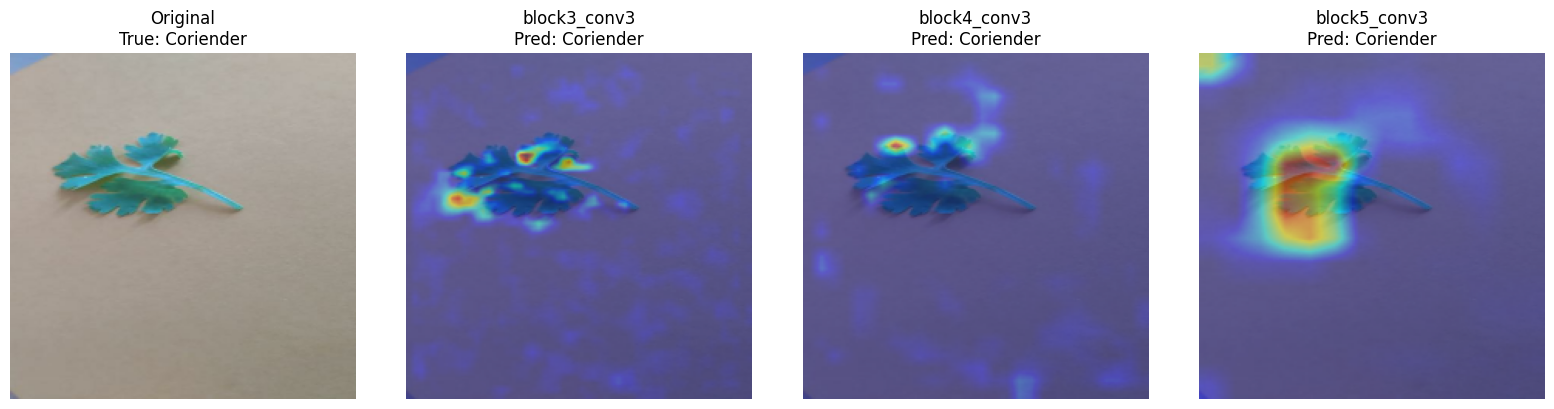

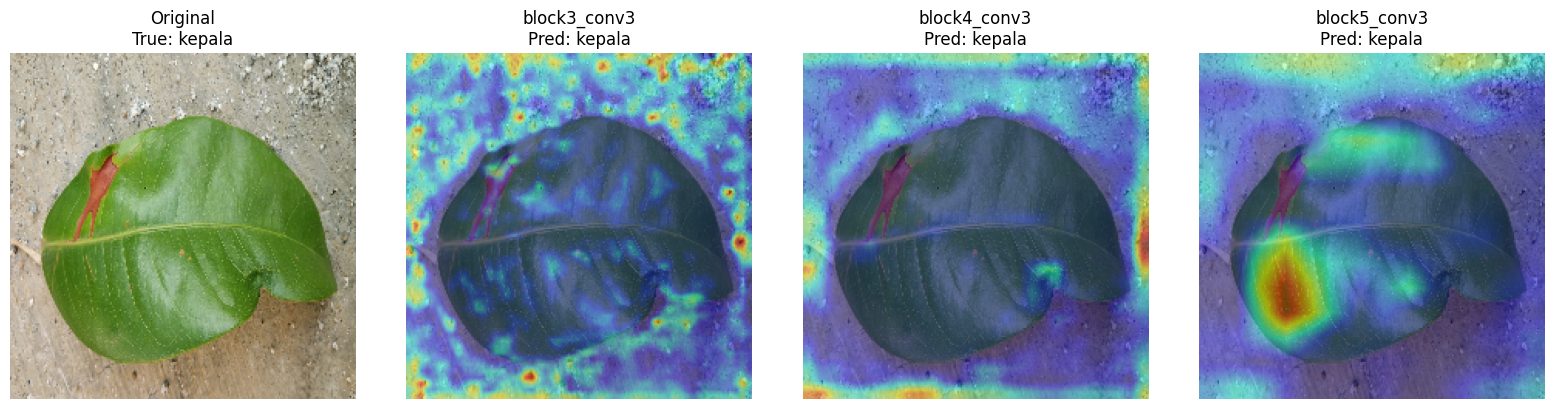

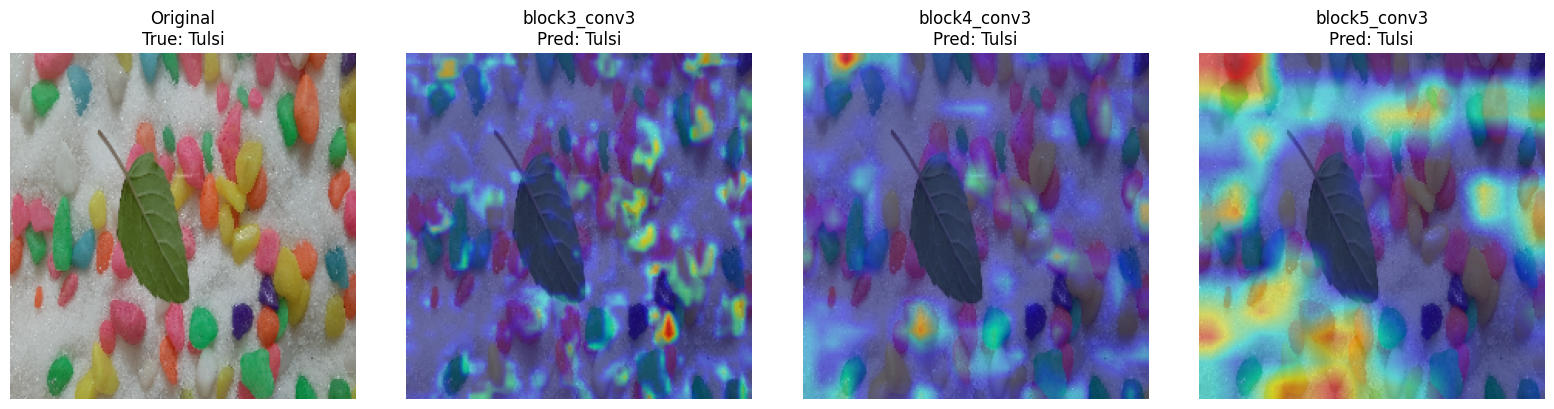

In [12]:
# ============================================================
# CELL 11 — GRAD-CAM ACROSS MULTIPLE LAYERS
# ============================================================
def get_gradcam_heatmap(img_array, model, layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    layer_output = layer_output[0]
    heatmap = layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)


def overlay_heatmap(orig_rgb_uint8, heatmap, alpha=0.45):
    import cv2
    heatmap_resized = cv2.resize(heatmap, (orig_rgb_uint8.shape[1], orig_rgb_uint8.shape[0]))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    return np.uint8(orig_rgb_uint8 * (1 - alpha) + heatmap_color * alpha)


LAYERS_TO_COMPARE = ["block3_conv3", "block4_conv3", "block5_conv3"]

# Pick a few random correctly-classified test images
rng = np.random.RandomState(RANDOM_STATE)
correct_positions = np.where(y_te == y_test_pred)[0]
sample_positions = rng.choice(correct_positions, size=min(3, len(correct_positions)), replace=False)

for pos in sample_positions:
    img_path = paths_te[pos]
    raw = tf.io.read_file(img_path)
    raw = tf.image.decode_image(raw, channels=3, expand_animations=False)
    raw = tf.image.resize(raw, [IMG_SIZE, IMG_SIZE])
    orig_uint8 = raw.numpy().astype("uint8")
    img_array = preprocess_input(raw.numpy().copy())[np.newaxis, ...]

    true_label = label_encoder.classes_[y_te[pos]]

    fig, axes = plt.subplots(1, len(LAYERS_TO_COMPARE) + 1, figsize=(4 * (len(LAYERS_TO_COMPARE) + 1), 4))
    axes[0].imshow(orig_uint8); axes[0].set_title(f"Original\nTrue: {true_label}"); axes[0].axis("off")

    for i, layer_name in enumerate(LAYERS_TO_COMPARE, start=1):
        heatmap, pred_idx = get_gradcam_heatmap(img_array, model, layer_name)
        overlay = overlay_heatmap(orig_uint8, heatmap)
        pred_label = label_encoder.classes_[pred_idx]
        axes[i].imshow(overlay)
        axes[i].set_title(f"{layer_name}\nPred: {pred_label}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"gradcam_{os.path.basename(img_path)}.png"), dpi=150)
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


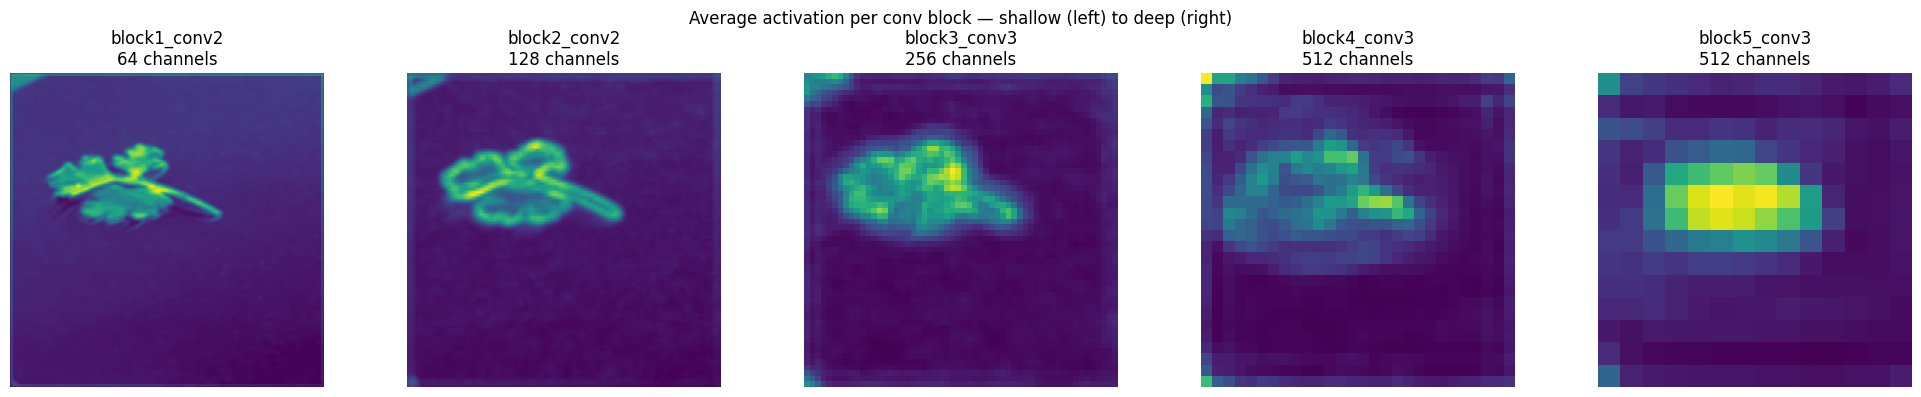

In [13]:
# ============================================================
# CELL 12 — FEATURE MAP VISUALIZATION (what each block "sees")
# ============================================================
FEATURE_LAYERS = ["block1_conv2", "block2_conv2", "block3_conv3", "block4_conv3", "block5_conv3"]

feature_extractor = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[model.get_layer(name).output for name in FEATURE_LAYERS]
)

sample_pos = sample_positions[0]
img_path = paths_te[sample_pos]
raw = tf.io.read_file(img_path)
raw = tf.image.decode_image(raw, channels=3, expand_animations=False)
raw = tf.image.resize(raw, [IMG_SIZE, IMG_SIZE])
img_array = preprocess_input(raw.numpy().copy())[np.newaxis, ...]

feature_maps = feature_extractor.predict(img_array)

fig, axes = plt.subplots(1, len(FEATURE_LAYERS), figsize=(20, 4))
for ax, name, fmap in zip(axes, FEATURE_LAYERS, feature_maps):
    # average across channels to get one representative activation map per block
    avg_map = fmap[0].mean(axis=-1)
    ax.imshow(avg_map, cmap="viridis")
    ax.set_title(f"{name}\n{fmap.shape[-1]} channels")
    ax.axis("off")
plt.suptitle("Average activation per conv block — shallow (left) to deep (right)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "vgg16_feature_maps.png"), dpi=150)
plt.show()


In [14]:
# ============================================================
# CELL 13 — SAVE RESULTS FOR TEAM COMPARISON
# ============================================================
result_row = pd.DataFrame([{
    "model": MODEL_TAG,
    "accuracy": test_acc,
    "precision_macro": test_prec,
    "recall_macro": test_rec,
    "f1_macro": test_f1,
    "epochs_stage1": len(history1.history["accuracy"]),
    "epochs_stage2": len(history2.history["accuracy"]),
    "fine_tuned_from": FINE_TUNE_FROM,
    "img_size": IMG_SIZE,
    "random_state": RANDOM_STATE,
}])

result_path = os.path.join(OUTPUT_DIR, "vgg16_results.csv")
result_row.to_csv(result_path, index=False)
print(f"Saved -> {result_path}")
print("\nShare this CSV with your teammates so the architecture-comparison table can be merged:")
print(result_row.to_string(index=False))

model.save(os.path.join(OUTPUT_DIR, "vgg16_final_model.keras"))
print(f"Saved final model -> {OUTPUT_DIR}/vgg16_final_model.keras")


Saved -> /kaggle/working/vgg16_results.csv

Share this CSV with your teammates so the architecture-comparison table can be merged:
model  accuracy  precision_macro  recall_macro  f1_macro  epochs_stage1  epochs_stage2 fine_tuned_from  img_size  random_state
VGG16  0.899517         0.908272      0.899211  0.897085             15             10    block5_conv1       224            42
Saved final model -> /kaggle/working/vgg16_final_model.keras
